In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt


In [2]:
# Unduh dan normalisasi dataset CIFAR-10
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()
train_images, test_images = train_images / 255.0, test_images / 255.0

print('Dimensi data latih:', train_images.shape)
print('Dimensi data uji  :', test_images.shape)


        0/170498071 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

    16384/170498071 ━━━━━━━━━━━━━━━━━━━━ 13:01 5us/step

    32768/170498071 ━━━━━━━━━━━━━━━━━━━━ 16:07 6us/step

    49152/170498071 ━━━━━━━━━━━━━━━━━━━━ 16:01 6us/step

    65536/170498071 ━━━━━━━━━━━━━━━━━━━━ 14:13 5us/step

    81920/170498071 ━━━━━━━━━━━━━━━━━━━━ 16:14 6us/step

... (1,382 outputs left out)

170106880/170498071 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step

170401792/170498071 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 98s 1us/step


Dimensi data latih: (50000, 32, 32, 3)
Dimensi data uji  : (10000, 32, 32, 3)


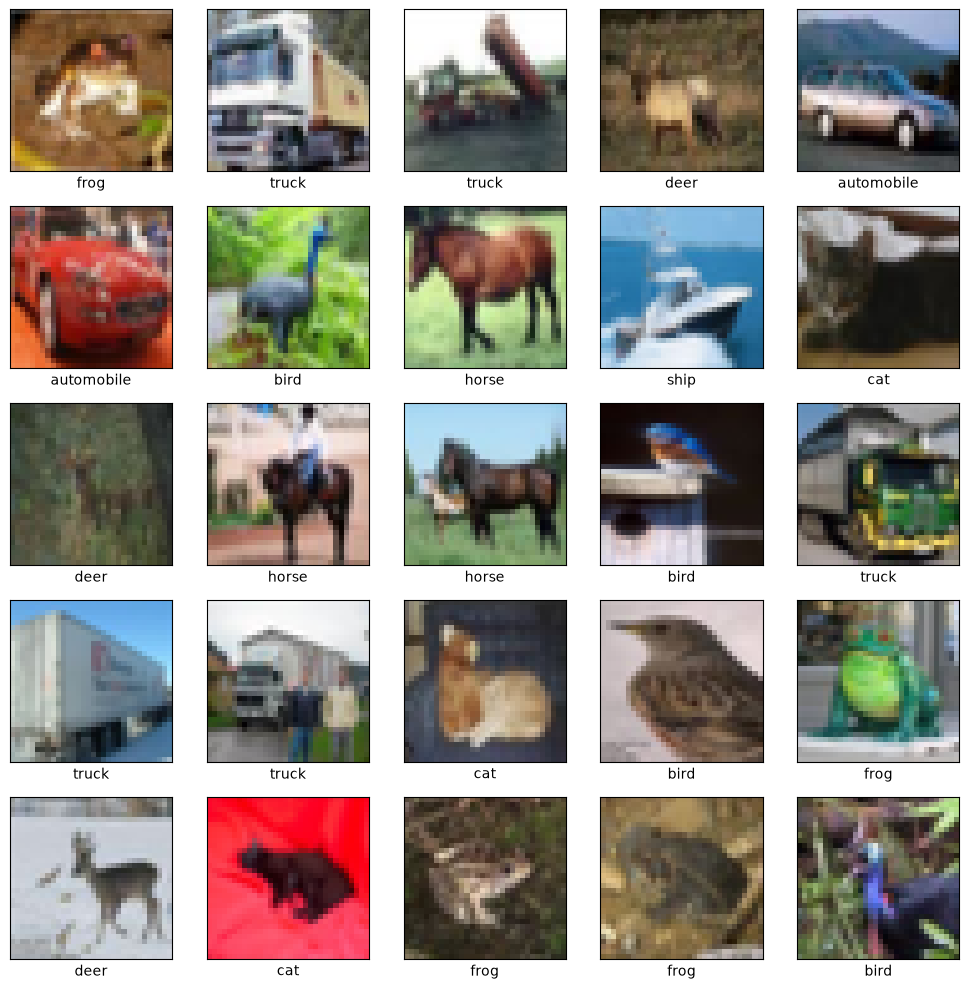

In [3]:
# Verifikasi sampel data citra
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i][0]])
plt.tight_layout()
plt.show()


In [4]:
tf.random.set_seed(42)

# Bangun arsitektur CNN baseline CIFAR-10
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10)
])

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)
model.summary()


C:\Users\azure\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Pelatihan model CNN
history = model.fit(
    train_images, train_labels,
    epochs=10,
    batch_size=64,
    validation_data=(test_images, test_labels)
)


Epoch 1/10


  1/782 ━━━━━━━━━━━━━━━━━━━━ 24:35 2s/step - accuracy: 0.1094 - loss: 2.3113

  5/782 ━━━━━━━━━━━━━━━━━━━━ 12s 16ms/step - accuracy: 0.1125 - loss: 2.3017

  9/782 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.1111 - loss: 2.3025

 13/782 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.1190 - loss: 2.2990

 17/782 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.1314 - loss: 2.2927

... (1,979 outputs left out)

773/782 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7545 - loss: 0.7026

777/782 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7546 - loss: 0.7023

781/782 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7547 - loss: 0.7016

782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.7548 - loss: 0.7015 - val_accuracy: 0.6892 - val_loss: 0.9166


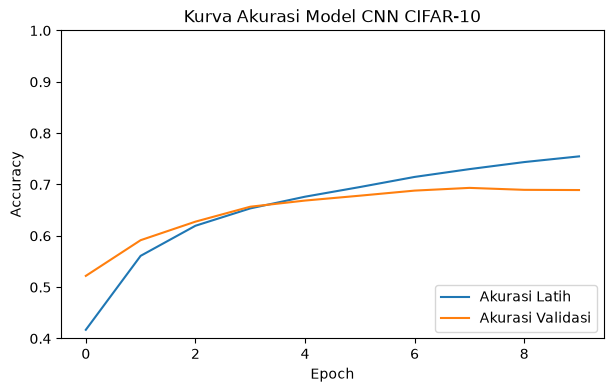

313/313 - 1s - 4ms/step - accuracy: 0.6892 - loss: 0.9166


Test Loss    : 0.9166
Test Accuracy: 68.92%


In [6]:
# Evaluasi performa dan visualisasi kurva akurasi
plt.figure(figsize=(7, 4))
plt.plot(history.history['accuracy'], label='Akurasi Latih')
plt.plot(history.history['val_accuracy'], label='Akurasi Validasi')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.4, 1.0])
plt.title('Kurva Akurasi Model CNN CIFAR-10')
plt.legend(loc='lower right')
plt.show()

test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print(f'Test Loss    : {test_loss:.4f}')
print(f'Test Accuracy: {test_acc * 100:.2f}%')
